In [74]:
import pandas as pd
import seaborn as sns
from matplotlib.pyplot import xticks
import warnings
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr,chi2_contingency

In [5]:
bmw = pd.read_csv('bmw.csv')
bmw.shape

(10781, 9)

In [6]:
bmw.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='object')

In [7]:
bmw.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,5 Series,2014,11200,Automatic,67068,Diesel,125,57.6,2.0
1,6 Series,2018,27000,Automatic,14827,Petrol,145,42.8,2.0
2,5 Series,2016,16000,Automatic,62794,Diesel,160,51.4,3.0
3,1 Series,2017,12750,Automatic,26676,Diesel,145,72.4,1.5
4,7 Series,2014,14500,Automatic,39554,Diesel,160,50.4,3.0


In [8]:
bmw.describe()

,year,price,mileage,tax,mpg,engineSize
count,10781.000000,10781.000000,10781.000000,10781.000000,10781.000000,10781.000000
mean,2017.078935,22733.408867,25496.986550,131.702068,56.399035,2.167767
std,2.349038,11415.528189,25143.192559,61.510755,31.336958,0.552054
min,1996.000000,1200.000000,1.000000,0.000000,5.500000,0.000000
25%,2016.000000,14950.000000,5529.000000,135.000000,45.600000,2.000000
50%,2017.000000,20462.000000,18347.000000,145.000000,53.300000,2.000000
75%,2019.000000,27940.000000,38206.000000,145.000000,62.800000,2.000000
max,2020.000000,123456.000000,214000.000000,580.000000,470.800000,6.600000


In [9]:
bmw.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

<Axes: >

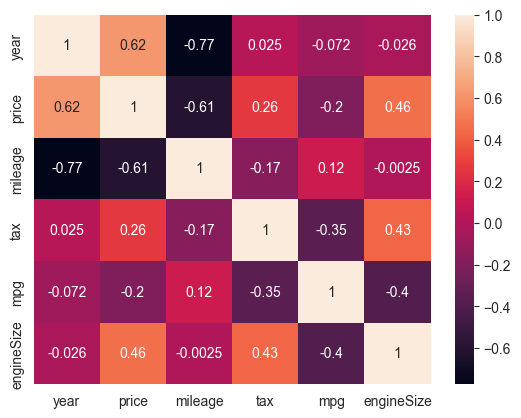

In [11]:
sns.heatmap(bmw.corr(numeric_only=True), annot=True)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24],
 [Text(0, 0, '1996'),
  Text(1, 0, '1997'),
  Text(2, 0, '1998'),
  Text(3, 0, '1999'),
  Text(4, 0, '2000'),
  Text(5, 0, '2001'),
  Text(6, 0, '2002'),
  Text(7, 0, '2003'),
  Text(8, 0, '2004'),
  Text(9, 0, '2005'),
  Text(10, 0, '2006'),
  Text(11, 0, '2007'),
  Text(12, 0, '2008'),
  Text(13, 0, '2009'),
  Text(14, 0, '2010'),
  Text(15, 0, '2011'),
  Text(16, 0, '2012'),
  Text(17, 0, '2013'),
  Text(18, 0, '2014'),
  Text(19, 0, '2015'),
  Text(20, 0, '2016'),
  Text(21, 0, '2017'),
  Text(22, 0, '2018'),
  Text(23, 0, '2019'),
  Text(24, 0, '2020')])

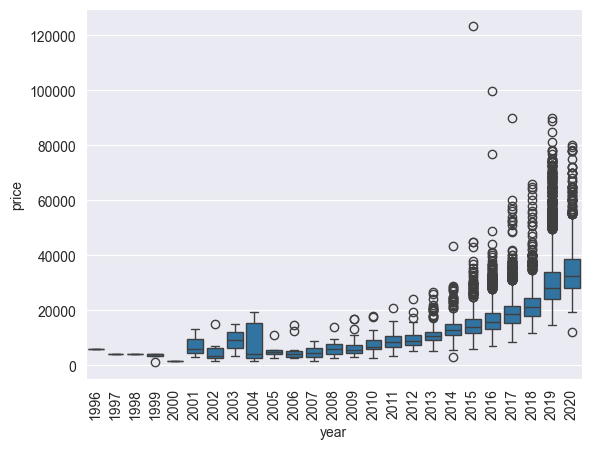

In [18]:
sns.boxplot(data=bmw,x='year',y='price')
xticks(rotation=90)

<Axes: xlabel='mileage', ylabel='price'>

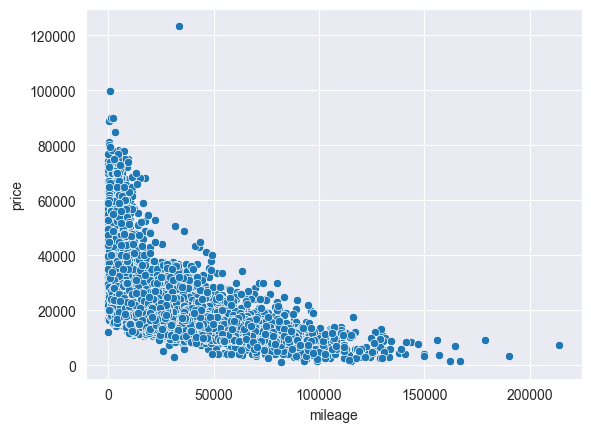

In [26]:
sns.scatterplot(data=bmw,x='mileage',y='price')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
 [Text(0, 0, '0.0'),
  Text(1, 0, '0.6'),
  Text(2, 0, '1.0'),
  Text(3, 0, '1.5'),
  Text(4, 0, '1.6'),
  Text(5, 0, '1.9'),
  Text(6, 0, '2.0'),
  Text(7, 0, '2.2'),
  Text(8, 0, '2.5'),
  Text(9, 0, '2.8'),
  Text(10, 0, '3.0'),
  Text(11, 0, '3.2'),
  Text(12, 0, '3.5'),
  Text(13, 0, '4.0'),
  Text(14, 0, '4.4'),
  Text(15, 0, '5.0'),
  Text(16, 0, '6.6')])

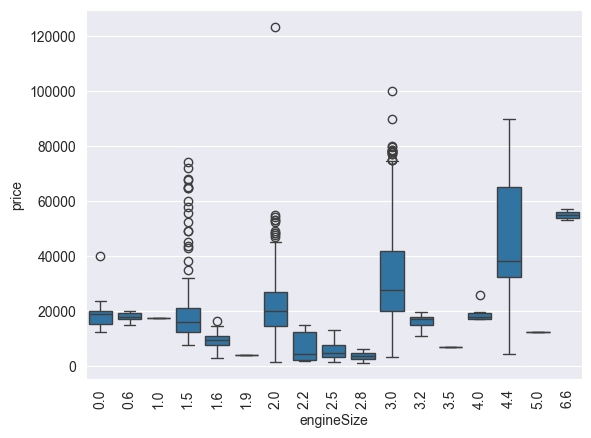

In [23]:
sns.boxplot(data=bmw,x='engineSize',y='price')
xticks(rotation=90)

<Axes: xlabel='mpg', ylabel='price'>

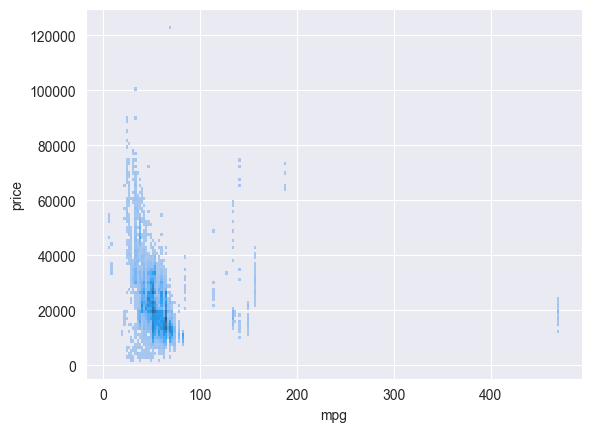

In [31]:
sns.histplot(data=bmw,x='mpg',y='price')

In [45]:
Bmw = bmw.copy()
Bmw

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,5 Series,2014,11200,Automatic,67068,Diesel,125,57.6,2.0
1,6 Series,2018,27000,Automatic,14827,Petrol,145,42.8,2.0
2,5 Series,2016,16000,Automatic,62794,Diesel,160,51.4,3.0
3,1 Series,2017,12750,Automatic,26676,Diesel,145,72.4,1.5
4,7 Series,2014,14500,Automatic,39554,Diesel,160,50.4,3.0
...,...,...,...,...,...,...,...,...,...
10776,X3,2016,19000,Automatic,40818,Diesel,150,54.3,2.0
10777,5 Series,2016,14600,Automatic,42947,Diesel,125,60.1,2.0
10778,3 Series,2017,13100,Manual,25468,Petrol,200,42.8,2.0
10779,1 Series,2014,9930,Automatic,45000,Diesel,30,64.2,2.0


In [46]:
cat_cols = Bmw.select_dtypes(include=object).columns
for col in cat_cols:
    print(col, ':',Bmw[col].unique())

model : [' 5 Series' ' 6 Series' ' 1 Series' ' 7 Series' ' 2 Series' ' 4 Series'
 ' X3' ' 3 Series' ' X5' ' X4' ' i3' ' X1' ' M4' ' X2' ' X6' ' 8 Series'
 ' Z4' ' X7' ' M5' ' i8' ' M2' ' M3' ' M6' ' Z3']
transmission : ['Automatic' 'Manual' 'Semi-Auto']
fuelType : ['Diesel' 'Petrol' 'Other' 'Hybrid' 'Electric']


In [47]:
Bmw = pd.get_dummies(Bmw,columns=cat_cols,drop_first=True,dtype=int)
Bmw

,year,price,mileage,tax,mpg,engineSize,model_ 2 Series,model_ 3 Series,model_ 4 Series,model_ 5 Series,...,model_ Z3,model_ Z4,model_ i3,model_ i8,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,2014,11200,67068,125,57.6,2.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,2018,27000,14827,145,42.8,2.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,2016,16000,62794,160,51.4,3.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2017,12750,26676,145,72.4,1.5,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2014,14500,39554,160,50.4,3.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10776,2016,19000,40818,150,54.3,2.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10777,2016,14600,42947,125,60.1,2.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
10778,2017,13100,25468,200,42.8,2.0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
10779,2014,9930,45000,30,64.2,2.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [57]:
cols = ['year','mileage','engineSize','mpg','tax']
scaler = StandardScaler()

Bmw[cols]=scaler.fit_transform(Bmw[cols])

In [55]:
Bmw

,year,price,mileage,tax,mpg,engineSize,model_ 2 Series,model_ 3 Series,model_ 4 Series,model_ 5 Series,...,model_ Z3,model_ Z4,model_ i3,model_ i8,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,-1.310782,11200,1.653447,-0.108963,0.038326,-0.303911,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,0.392121,27000,-0.424388,0.216199,-0.433982,-0.303911,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,-0.459331,16000,1.483453,0.460070,-0.159533,1.507591,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,-0.033605,12750,0.046894,0.216199,0.510634,-1.209662,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,-1.310782,14500,0.559104,0.460070,-0.191445,1.507591,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10776,-0.459331,19000,0.609379,0.297489,-0.066986,-0.303911,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10777,-0.459331,14600,0.694058,-0.108963,0.118108,-0.303911,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
10778,-0.033605,13100,-0.001153,1.110393,-0.433982,-0.303911,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
10779,-1.310782,9930,0.775714,-1.653480,0.248950,-0.303911,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [60]:
Bmw.columns

Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize',
       'model_ 2 Series', 'model_ 3 Series', 'model_ 4 Series',
       'model_ 5 Series', 'model_ 6 Series', 'model_ 7 Series',
       'model_ 8 Series', 'model_ M2', 'model_ M3', 'model_ M4', 'model_ M5',
       'model_ M6', 'model_ X1', 'model_ X2', 'model_ X3', 'model_ X4',
       'model_ X5', 'model_ X6', 'model_ X7', 'model_ Z3', 'model_ Z4',
       'model_ i3', 'model_ i8', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Electric', 'fuelType_Hybrid',
       'fuelType_Other', 'fuelType_Petrol'],
      dtype='object')

In [59]:
selected_features = Bmw.drop('price',axis=1)
Correlation = {feature : pearsonr(Bmw[feature], Bmw['price'])[0]
               for feature in selected_features
               }
corr_df = pd.DataFrame(list(Correlation.items()), columns=['Feature', 'Value'])
corr_df.sort_values(by='Value', ascending=False, inplace=True)
print(corr_df)

                   Feature     Value
0                     year  0.623756
4               engineSize  0.460196
29  transmission_Semi-Auto  0.354026
21               model_ X5  0.315717
23               model_ X7  0.295525
2                      tax  0.263484
11         model_ 8 Series  0.217816
14               model_ M4  0.194895
22               model_ X6  0.184239
15               model_ M5  0.159359
10         model_ 7 Series  0.123968
27               model_ i8  0.119342
20               model_ X4  0.113693
19               model_ X3  0.102162
33         fuelType_Petrol  0.097082
18               model_ X2  0.083500
12               model_ M2  0.078978
31         fuelType_Hybrid  0.065526
25               model_ Z4  0.037616
13               model_ M3  0.032906
16               model_ M6  0.022575
9          model_ 6 Series  0.014285
8          model_ 5 Series -0.005658
30       fuelType_Electric -0.006237
7          model_ 4 Series -0.006564
26               model_ i3 -0.022542
3

In [61]:
cat_features = ['model_ 2 Series', 'model_ 3 Series', 'model_ 4 Series',
       'model_ 5 Series', 'model_ 6 Series', 'model_ 7 Series',
       'model_ 8 Series', 'model_ M2', 'model_ M3', 'model_ M4', 'model_ M5',
       'model_ M6', 'model_ X1', 'model_ X2', 'model_ X3', 'model_ X4',
       'model_ X5', 'model_ X6', 'model_ X7', 'model_ Z3', 'model_ Z4',
       'model_ i3', 'model_ i8', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Electric', 'fuelType_Hybrid',
       'fuelType_Other', 'fuelType_Petrol']

In [64]:
alpha = 0.05
chi2_result = {}

for col in cat_features:
    contingency = pd.crosstab(Bmw[col],Bmw['price'])
    chi_stat2,p_value,_,_ = chi2_contingency(contingency)
    decision = 'Accept NUll(Drop Feature)' if p_value > alpha else 'Reject NULL(Keep Feature)'
    chi2_result[col] = {
        'chi2_statistics':chi_stat2,
        'p_value':p_value,
        'decision':decision
    }
chi2_df = pd.DataFrame(chi2_result).T
chi2_df.sort_values(by='p_value', ascending=False, inplace=True)
print(chi2_df)

                       chi2_statistics   p_value                   decision
fuelType_Other              1733.73269       1.0  Accept NUll(Drop Feature)
fuelType_Electric          1041.164325       1.0  Accept NUll(Drop Feature)
model_ i3                  2634.229187       1.0  Accept NUll(Drop Feature)
model_ M6                  3770.412736  0.522589  Accept NUll(Drop Feature)
model_ X1                  3855.675501  0.179276  Accept NUll(Drop Feature)
model_ 3 Series            4042.395907  0.001333  Reject NULL(Keep Feature)
fuelType_Hybrid            4193.662958  0.000002  Reject NULL(Keep Feature)
model_ Z4                  4208.324853  0.000001  Reject NULL(Keep Feature)
model_ 4 Series            4244.090067       0.0  Reject NULL(Keep Feature)
model_ 5 Series            4253.166579       0.0  Reject NULL(Keep Feature)
model_ M3                  4292.670342       0.0  Reject NULL(Keep Feature)
model_ 2 Series            4307.975659       0.0  Reject NULL(Keep Feature)
fuelType_Pet

In [67]:
final_bmw = Bmw[['year', 'mileage', 'tax', 'mpg', 'engineSize','model_ 2 Series', 'model_ 3 Series', 'model_ 4 Series',
       'model_ 5 Series', 'model_ 6 Series', 'model_ 7 Series',
       'model_ 8 Series', 'model_ M2', 'model_ M3', 'model_ M4', 'model_ M5',
       'model_ X2', 'model_ X3', 'model_ X4',
       'model_ X5', 'model_ X6', 'model_ X7', 'model_ Z3', 'model_ Z4',
       'model_ i8', 'transmission_Manual',
       'transmission_Semi-Auto', 'fuelType_Hybrid',
       'fuelType_Petrol', 'price']]
final_bmw.shape

(10781, 30)

In [69]:
X=final_bmw.drop('price',axis=1)
Y=final_bmw['price']

In [75]:
X_train,X_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [76]:
model = LinearRegression()
model.fit(X_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](29,)","[ 4107.54,-2973.85, -97.26,..., 1051.38, 3325.9 , 785.5 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](29,)","['year','mileage','tax',...,'transmission_Semi-Auto','fuelType_Hybrid', 'fuelType_Petrol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.879e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,29
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,29


In [79]:
y_pred = model.predict(X_test)
r2 = r2_score(y_test,y_pred)
round(r2,4)

0.8411

In [85]:
n = X_train.shape[0]
P = X_train.shape[1]
AR = 1-((1-r2)*(n-1)/(n-P-1))
round(AR,4)

0.8406